# 15 – D24: RC-TFT, the literature baselines, and the Spark preprocessing job

This notebook only **reads** committed results files and figures; it trains nothing and starts no Spark job.

- **Sources:** `results/forecasting_d24_e1.json` (E1, horizons 1–3) and `results/forecasting_d24_e2.json` (E2, horizons 1–6), pre-registered as D24 in `docs/DECISIONS.md`, run 13–14 Oct 2026 at a clean commit. They also carry the committed D23 runs (residual and direct TFT and MLP), which were checked to reproduce before use. Spark: `results/s6_ageing_row_count.json`, `results/d22_ageing_report.json`, `results/d22_spark_validation.json`, `results/d22_spark_scaling.json`.
- **Data:** S6 (Wheeler et al. 2025), seven test cases streamed as continual-learning tasks.
- **Metric:** final average test RMSE in percentage points (pp) of SOH; SOH is relative to the first observed RPT capacity of each cell, not nominal capacity. Forgetting and backward transfer (BWT) in pp.
- **Runs:** 10 task orders × 5 seeds per seed set; *main* = seeds 0–4, *replicate* = seeds 5–9. Deterministic and fitted-once baselines have a single value.
- **Tests:** paired two-sided Wilcoxon against the reference **RC-TFT**, Holm-corrected within each seed set. `diff` = RC-TFT − other (negative = RC-TFT has lower error).
- **D21 replication rule:** a finding needs p_Holm < 0.05 in both seed sets, the same sign and |diff| ≥ 0.05 pp in both; |diff| < 0.05 pp in both is *practically equivalent*; anything else is *not replicated*.
- Tables come from the same code as the paper tables (`scripts/make_d24_outputs.py`).

In [1]:
import importlib.util
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts" / "make_d24_outputs.py").is_file())
spec = importlib.util.spec_from_file_location("d24_outputs", REPO_ROOT / "scripts" / "make_d24_outputs.py")
O = importlib.util.module_from_spec(spec)
spec.loader.exec_module(O)          # imports only; its main() (which writes files) is not called
%matplotlib inline

REF, FIXED = "tft_residual_saewc", "tft_residual_ewc"
data = {}
for exp in ("e1", "e2"):
    path = REPO_ROOT / "results" / f"forecasting_d24_{exp}.json"
    data[exp] = json.loads(path.read_text(encoding="utf-8"))
    d, env = data[exp], data[exp]["environment"]
    print(f"{exp}: {path.name}, decision {d['decision']}, profile {d['profile']}, horizons {d['horizons']}, "
          f"{d['n_samples']} samples, commit {env['git_commit'][:7]}, git_dirty={env['git_dirty']}, "
          f"parts not run: {d['parts_not_run'] or 'none'}")
    rep = d["d23_reference_reproduction"]
    print("   D23 reproduction check:", [(u["set"], round(u["recomputed"], 6), round(u["committed"], 6)) for u in rep["units"]])
print("kernel: Python", sys.version.split()[0], "| results environment:",
      {k: v for k, v in env.items() if k not in ("git_commit", "git_dirty")})

e1: forecasting_d24_e1.json, decision D24, profile paper, horizons [1, 2, 3], 2409 samples, commit 947b33a, git_dirty=False, parts not run: none
   D23 reproduction check: [('main', 0.464125, 0.464125), ('replicate', 0.375621, 0.375621)]
e2: forecasting_d24_e2.json, decision D24, profile paper, horizons [1, 2, 3, 4, 5, 6], 4638 samples, commit 947b33a, git_dirty=False, parts not run: none
   D23 reproduction check: [('main', 0.480461, 0.480461), ('replicate', 0.880787, 0.880787)]
kernel: Python 3.11.15 | results environment: {'python': '3.12.10', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scikit-learn': '1.5.2', 'torch': '2.13.0+cpu'}


## 1. Final test RMSE of every method

In [2]:
comp = {}
for exp in ("e1", "e2"):
    c = O.comparison(data[exp])
    comp[exp] = c
    view = c[["label", "kind", "rmse_main_mean", "rmse_main_sd", "rmse_replicate_mean", "rmse_replicate_sd",
              "forgetting_main", "bwt_main", "parameters"]].rename(columns={
        "label": "method", "rmse_main_mean": "RMSE main (pp)", "rmse_main_sd": "s.d. main",
        "rmse_replicate_mean": "RMSE replicate (pp)", "rmse_replicate_sd": "s.d. replicate",
        "forgetting_main": "forgetting main (pp)", "bwt_main": "BWT main (pp)"})
    print(f"{exp.upper()} (horizons {data[exp]['horizons']}), sorted by main RMSE")
    display(view.round(3))

E1 (horizons [1, 2, 3]), sorted by main RMSE


,method,kind,RMSE main (pp),s.d. main,RMSE replicate (pp),s.d. replicate,forgetting main (pp),BWT main (pp),parameters
0,"BiLSTM + EWC, direct",continual (stream),0.323,0.099,0.323,0.085,0.053,0.023,11181.0
1,"BiLSTM + EWC, residual",continual (stream),0.328,0.109,0.370,0.154,0.091,0.000,11181.0
2,"TFT + EWC, residual",continual (stream),0.339,0.164,0.314,0.067,0.100,0.040,12708.0
3,Linear extrapolation,deterministic,0.343,NaN,0.343,NaN,NaN,NaN,NaN
4,RC-TFT (residual TFT + SA-EWC),continual (stream),0.343,0.108,0.321,0.091,0.100,0.044,12708.0
5,"BiLSTM fine-tuning, residual",continual (stream),0.346,0.130,0.349,0.114,0.104,0.015,11181.0
6,"TFT fine-tuning, residual",continual (stream),0.347,0.121,0.337,0.110,0.103,0.045,12708.0
7,"Transformer + EWC, residual",continual (stream),0.360,0.076,0.366,0.083,0.064,0.037,11905.0
8,"MLP + EWC, residual",continual (stream),0.374,0.056,0.366,0.071,0.053,0.036,NaN
9,"Transformer fine-tuning, residual",continual (stream),0.377,0.126,0.415,0.205,0.121,0.051,11905.0


E2 (horizons [1, 2, 3, 4, 5, 6]), sorted by main RMSE


,method,kind,RMSE main (pp),s.d. main,RMSE replicate (pp),s.d. replicate,forgetting main (pp),BWT main (pp),parameters
0,Linear extrapolation,deterministic,0.485,NaN,0.485,NaN,NaN,NaN,NaN
1,RC-TFT (residual TFT + SA-EWC),continual (stream),0.548,0.128,0.564,0.158,0.066,0.015,12708.0
2,"TFT + EWC, residual",continual (stream),0.561,0.152,0.534,0.124,0.093,0.032,12708.0
3,"Transformer + EWC, residual",continual (stream),0.609,0.165,0.705,0.244,0.129,0.071,11905.0
4,"SVR, residual",fitted once on all tasks,0.616,NaN,0.616,NaN,NaN,NaN,NaN
5,"MLP fine-tuning, residual",continual (stream),0.656,0.202,0.695,0.213,0.201,0.150,NaN
6,"TFT fine-tuning, direct",continual (stream),0.658,0.400,0.694,0.418,0.307,0.065,12708.0
7,"MLP + EWC, residual",continual (stream),0.659,0.208,0.694,0.217,0.205,0.154,NaN
8,"BiLSTM + EWC, residual",continual (stream),0.669,0.196,0.765,0.299,0.229,0.103,11181.0
9,"TFT fine-tuning, residual",continual (stream),0.673,0.270,0.612,0.229,0.282,0.177,12708.0


## 2. Registered primary tests

Primary family (one Holm family per seed set): RC-TFT against (a) the same residual TFT with a fixed EWC λ (D23), on final error and forgetting, and (b) linear extrapolation, on final error. **Criterion for SA-EWC:** (a) replicated in favour of RC-TFT on final error or forgetting, and not replicated against it on the other.

In [3]:
tests = {exp: O.tests_table(data[exp]) for exp in ("e1", "e2")}
cols = ["metric", "other", "diff_main", "ci_main", "p_holm_main", "diff_replicate", "p_holm_replicate", "verdict"]
for exp in ("e1", "e2"):
    t = tests[exp]
    print(f"{exp.upper()}: reference = {t['reference'].iloc[0]}")
    display(t[t["family"] == "primary"][cols].round({"diff_main": 3, "diff_replicate": 3})
            .style.format({"p_holm_main": "{:.2g}", "p_holm_replicate": "{:.2g}"}))

E1: reference = RC-TFT (residual TFT + SA-EWC)


,metric,other,diff_main,ci_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
0,final_avg_error,"TFT + EWC, residual",0.004000,"[-0.044, 0.046]",1,0.007000,0.33,practically equivalent
1,forgetting,"TFT + EWC, residual",0.000000,"[-0.050, 0.046]",1,0.007000,0.7,practically equivalent
2,final_avg_error,Linear extrapolation,0.000000,"[-0.028, 0.031]",1,-0.022000,0.047,practically equivalent


E2: reference = RC-TFT (residual TFT + SA-EWC)


,metric,other,diff_main,ci_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
0,final_avg_error,"TFT + EWC, residual",-0.013000,"[-0.044, 0.015]",0.33,0.030000,0.38,practically equivalent
1,forgetting,"TFT + EWC, residual",-0.027000,"[-0.057, -0.001]",0.08,-0.002000,0.92,practically equivalent
2,final_avg_error,Linear extrapolation,0.063000,"[0.029, 0.100]",0.011,0.079000,0.06,not replicated


## 3. Which TFT? All TFT variants side by side

RC-TFT (shift-adaptive EWC), the residual TFT with fixed-λ EWC, residual fine-tuning, and the direct forms.

In [4]:
tft = ["tft_residual_saewc", "tft_residual_ewc", "tft_residual_finetune", "tft_direct_ewc", "tft_direct_finetune"]
rows = []
for exp in ("e1", "e2"):
    c = comp[exp].set_index("method")
    for m in tft:
        r = c.loc[m]
        rows.append({"experiment": exp.upper(), "method": r["label"], "RMSE main (pp)": r["rmse_main_mean"],
                     "RMSE replicate (pp)": r["rmse_replicate_mean"], "forgetting main (pp)": r["forgetting_main"],
                     "train time per stream (s)": r["train_time_s"]})
display(pd.DataFrame(rows).round(3))
t = pd.concat([tests[e].assign(experiment=e.upper()) for e in ("e1", "e2")])
tft_labels = [O.label(m) for m in tft[1:]]
display(t[(t["other"].isin(tft_labels)) & (t["metric"] == "final_avg_error")]
        [["experiment", "other", "diff_main", "diff_replicate", "verdict"]].round(3))

,experiment,method,RMSE main (pp),RMSE replicate (pp),forgetting main (pp),train time per stream (s)
0,E1,RC-TFT (residual TFT + SA-EWC),0.343,0.321,0.100,54.193
1,E1,"TFT + EWC, residual",0.339,0.314,0.100,39.189
2,E1,"TFT fine-tuning, residual",0.347,0.337,0.103,24.258
3,E1,"TFT + EWC, direct",0.504,0.487,0.228,36.411
4,E1,"TFT fine-tuning, direct",0.424,0.444,0.151,22.011
5,E2,RC-TFT (residual TFT + SA-EWC),0.548,0.564,0.066,47.536
6,E2,"TFT + EWC, residual",0.561,0.534,0.093,55.622
7,E2,"TFT fine-tuning, residual",0.673,0.612,0.282,40.773
8,E2,"TFT + EWC, direct",0.802,0.835,0.135,60.124
9,E2,"TFT fine-tuning, direct",0.658,0.694,0.307,36.945


,experiment,other,diff_main,diff_replicate,verdict
0,E1,"TFT + EWC, residual",0.004,0.007,practically equivalent
39,E1,"TFT + EWC, direct",-0.161,-0.166,"replicated, reference better"
42,E1,"TFT fine-tuning, direct",-0.081,-0.123,not replicated
45,E1,"TFT + EWC, residual",0.004,0.007,practically equivalent
48,E1,"TFT fine-tuning, residual",-0.004,-0.016,practically equivalent
0,E2,"TFT + EWC, residual",-0.013,0.030,practically equivalent
27,E2,"TFT + EWC, direct",-0.254,-0.270,"replicated, reference better"
30,E2,"TFT fine-tuning, direct",-0.111,-0.130,not replicated
33,E2,"TFT + EWC, residual",-0.013,0.030,practically equivalent
36,E2,"TFT fine-tuning, residual",-0.125,-0.048,not replicated


## 4. RC-TFT against the literature backbones and the classical regressors (final error)

BiLSTM, TCN and Transformer are continual learners (fine-tuning and EWC) with the TFT's input window, sized within 20 % of its parameter count. GPR, random forest, SVR, gradient boosting and ridge are **single fits on all tasks' training rows**, not continual learners.

In [5]:
lit = ("lstm", "tcn", "transformer", "gpr", "rf_", "svr", "gbm", "ridge", "persistence", "mlp")
for exp in ("e1", "e2"):
    t = tests[exp]
    t = t[(t["family"] != "primary") & (t["metric"] == "final_avg_error")]
    t = t[t["other"].isin([O.label(m) for m in comp[exp]["method"] if m.startswith(lit)])]
    print(exp.upper())
    display(t[["other", "diff_main", "diff_replicate", "verdict"]].sort_values("diff_main").round(3))

E1


,other,diff_main,diff_replicate,verdict
69,"GPR, residual",-2.241,-2.264,"replicated, reference better"
63,Persistence,-1.301,-1.323,"replicated, reference better"
68,"GPR, direct",-1.031,-1.053,"replicated, reference better"
66,Ridge,-0.841,-0.863,"replicated, reference better"
65,"Ridge, usage only",-0.736,-0.758,"replicated, reference better"
71,"Random forest, residual",-0.626,-0.648,"replicated, reference better"
72,"SVR, direct",-0.499,-0.521,"replicated, reference better"
15,"MLP + EWC, direct",-0.176,-0.206,"replicated, reference better"
67,Gradient boosting,-0.167,-0.190,"replicated, reference better"
36,"TCN fine-tuning, residual",-0.160,-0.163,"replicated, reference better"


E2


,other,diff_main,diff_replicate,verdict
45,Persistence,-2.119,-2.103,"replicated, reference better"
51,"GPR, residual",-1.767,-1.751,"replicated, reference better"
48,Ridge,-1.653,-1.637,"replicated, reference better"
50,"GPR, direct",-1.526,-1.509,"replicated, reference better"
47,"Ridge, usage only",-1.105,-1.089,"replicated, reference better"
54,"SVR, direct",-0.748,-0.732,"replicated, reference better"
24,"TCN fine-tuning, residual",-0.499,-0.476,"replicated, reference better"
53,"Random forest, residual",-0.479,-0.463,"replicated, reference better"
9,"MLP + EWC, direct",-0.456,-0.432,"replicated, reference better"
52,"Random forest, direct",-0.399,-0.382,"replicated, reference better"


## 5. Figure: final test RMSE (main seed set, mean ± s.d. over 50 runs)

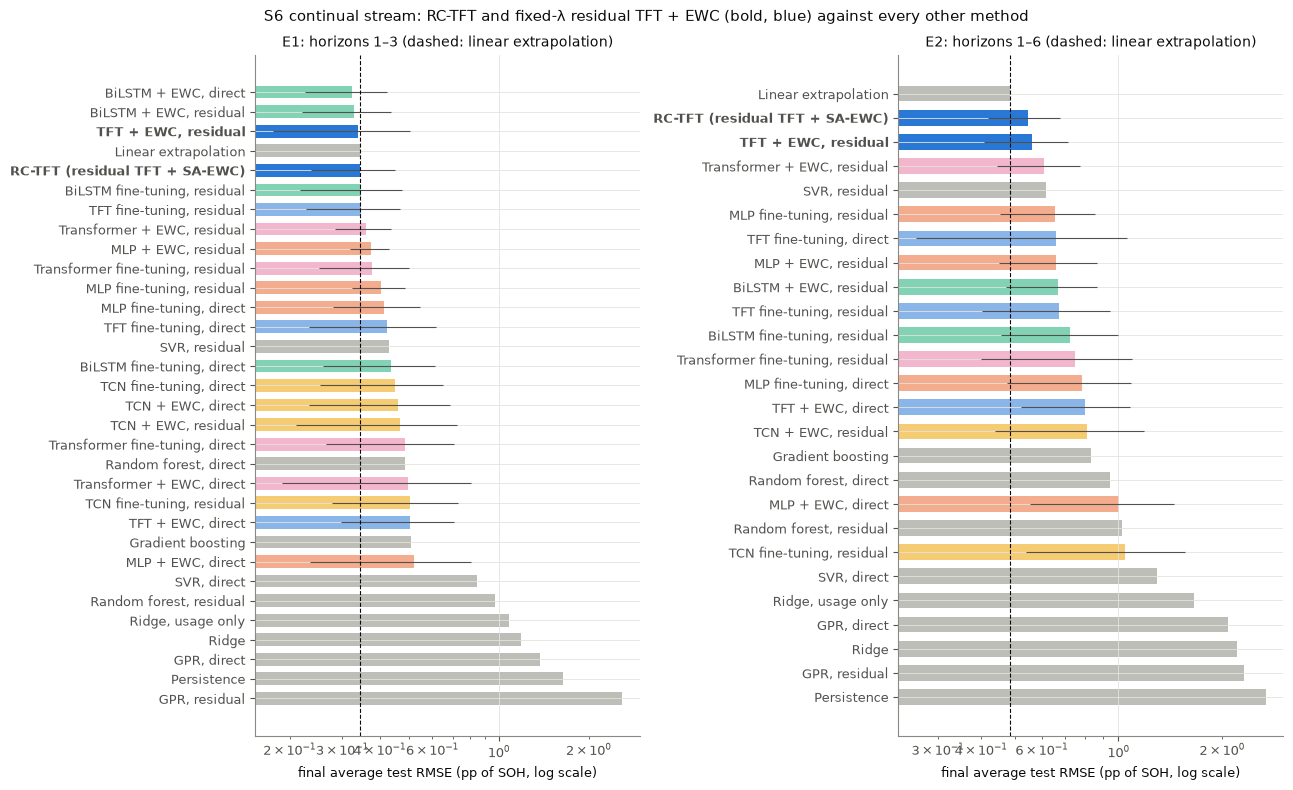

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
for ax, exp in zip(axes, ("e1", "e2")):
    c = comp[exp].sort_values("rmse_main_mean", ascending=False)
    colours = ["#2a78d6" if m in (REF, FIXED) else O.FAMILY_COLOUR.get(O.family(m), O.GREY) if O.family(m) else O.GREY
               for m in c["method"]]
    bars = ax.barh(c["label"], c["rmse_main_mean"], xerr=c["rmse_main_sd"].fillna(0), color=colours,
                   height=0.65, error_kw={"elinewidth": 0.8, "ecolor": O.INK2})
    for b, m in zip(bars, c["method"]):
        b.set_alpha(1.0 if m in (REF, FIXED) else 0.55)
    lin = c.loc[c["method"] == "linear_extrapolation", "rmse_main_mean"].iloc[0]
    ax.axvline(lin, color=O.INK, linestyle="--", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("final average test RMSE (pp of SOH, log scale)")
    ax.set_title(f"{exp.upper()}: horizons {data[exp]['horizons'][0]}–{data[exp]['horizons'][-1]} (dashed: linear extrapolation)")
    for lbl in ax.get_yticklabels():
        if lbl.get_text() in (O.label(REF), O.label(FIXED)):
            lbl.set_fontweight("bold")
fig.suptitle("S6 continual stream: RC-TFT and fixed-λ residual TFT + EWC (bold, blue) against every other method")
fig.tight_layout()
plt.show()

## 6. E2 per horizon: RC-TFT against linear extrapolation

In [7]:
t = tests["e2"]
h = t[t["metric"].str.startswith("rmse_h") & (t["other"] == O.label("linear_extrapolation"))]
display(h[["metric", "diff_main", "p_holm_main", "diff_replicate", "p_holm_replicate", "verdict"]].round(3))

,metric,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
56,rmse_h1,0.209,0.000,0.179,0.000,"replicated, reference worse"
57,rmse_h2,0.115,0.000,0.113,0.000,"replicated, reference worse"
58,rmse_h3,0.059,0.099,0.085,0.012,not replicated
59,rmse_h4,0.056,0.190,0.085,1.000,not replicated
60,rmse_h5,0.008,0.789,0.038,1.000,practically equivalent
61,rmse_h6,-0.029,0.166,-0.001,1.000,practically equivalent


## 7. Per test case (main seeds, test RMSE after the last stream step)

In [8]:
for exp in ("e1", "e2"):
    print(exp.upper())
    display(O.per_group(data[exp]).round(3))

E1


,case1,case2,case3,case4,case5,case6,case7,mean
"BiLSTM + EWC, direct",0.245,0.267,0.355,0.313,0.301,0.352,0.430,0.323
"BiLSTM + EWC, residual",0.232,0.265,0.317,0.287,0.260,0.461,0.472,0.328
"TFT + EWC, residual",0.286,0.311,0.333,0.320,0.302,0.378,0.443,0.339
Linear extrapolation,0.256,0.352,0.275,0.342,0.345,0.322,0.507,0.343
RC-TFT (residual TFT + SA-EWC),0.269,0.312,0.315,0.332,0.303,0.415,0.455,0.343
"BiLSTM fine-tuning, residual",0.256,0.285,0.375,0.293,0.271,0.441,0.504,0.346
"TFT fine-tuning, residual",0.281,0.308,0.352,0.310,0.294,0.424,0.461,0.347
"Transformer + EWC, residual",0.302,0.339,0.320,0.356,0.381,0.374,0.447,0.360
"MLP + EWC, residual",0.300,0.368,0.356,0.367,0.370,0.417,0.441,0.374
"Transformer fine-tuning, residual",0.305,0.322,0.336,0.358,0.355,0.512,0.448,0.377


E2


,case1,case2,case3,case4,case5,case6,case7,mean
Linear extrapolation,0.301,0.348,0.391,0.510,0.492,0.546,0.805,0.485
RC-TFT (residual TFT + SA-EWC),0.409,0.457,0.528,0.574,0.528,0.665,0.674,0.548
"TFT + EWC, residual",0.403,0.463,0.560,0.583,0.524,0.682,0.713,0.561
"Transformer + EWC, residual",0.484,0.487,0.649,0.606,0.586,0.707,0.744,0.609
"SVR, residual",0.321,0.585,0.388,0.584,0.829,0.832,0.774,0.616
"MLP fine-tuning, residual",0.484,0.530,0.661,0.707,0.675,0.886,0.648,0.656
"TFT fine-tuning, direct",0.657,0.583,0.869,0.516,0.619,0.688,0.679,0.658
"MLP + EWC, residual",0.485,0.532,0.662,0.713,0.679,0.892,0.649,0.659
"BiLSTM + EWC, residual",0.491,0.533,0.732,0.661,0.548,0.846,0.872,0.669
"TFT fine-tuning, residual",0.563,0.611,0.638,0.657,0.576,0.891,0.772,0.673


## 8. Reading the D24 results

- **The registered positive result for SA-EWC was not obtained.** RC-TFT and the fixed-λ residual TFT + EWC are practically equivalent on final error and forgetting in E1 and E2 (section 2). Under the rule fixed in D24, RC-TFT is reported with this outcome and **the fixed-λ residual TFT + EWC stays the best-supported variant**: same accuracy, one fewer mechanism.
- **No model beats linear extrapolation.** RC-TFT is level with it at horizons 1–3 and not better at 1–6; extrapolation is better at h = 1–2, replicated (section 6).
- **The residual form is what makes the TFT competitive.** Residual TFT variants beat the direct ones by 0.16–0.27 pp, replicated (section 3).
- **The TFT is not uniquely accurate at short horizons.** At horizons 1–3, BiLSTM + EWC (direct and residual) and the residual Transformer + EWC are practically equivalent to RC-TFT. Over horizons 1–6, RC-TFT beats the residual BiLSTM and TCN, replicated; the Transformer comparison is not replicated (section 4).
- **The learned continual models beat the classical regressors** (GPR, random forest, SVR, gradient boosting, ridge), replicated, except the residual SVR in E2. Those regressors see all tasks at once, so this is not a like-for-like continual-learning comparison.

## 9. The Spark preprocessing job: what it did

**The problem.** Between two capacity checks, every S6 cell runs 100 ageing cycles logged at about one sample per second. The forecasting models only see one row per check, so the raw ageing data has to be **reduced** to a few numbers per cell and 100-cycle block, without letting the label leak in. This is the project's big-data step (decision D22).

**The job** (`scripts/spark_ageing_features.py`, Apache Spark 4.2 / PySpark, local mode on one PC, no cluster):

1. **Input:** one task description per raw block file (`Cell*/agingdata_50degC/*aging*.csv.xz|gz`), with that cell's voltage limit and CC-CV setting.
2. **Map** (`sc.parallelize(jobs, len(jobs)).flatMap(parse_block)`): one Spark task per block. Each task decompresses and reads its file, splits it into charge / discharge / rest steps, and calls `src.ageing.cycle_responses` (the same tested function the pandas builder uses) to get, per cycle, a validity flag and seven measured responses: end-of-charge and end-of-discharge voltage, CV-hold time and final current, relaxation after charge and after discharge, internal resistance. Charge, energy and current are **excluded**, because the protocol sets them from the previous capacity (they would leak the label).
3. **Cache:** the per-cycle table (one row per cycle) is cached in Spark memory.
4. **Reduce** (Spark SQL `groupBy("cell", "block_end").agg(...)`): over the valid cycles of each block, the mean, the last value (`max_by` cycle) and the least-squares slope against cycle number (`covar_pop / var_pop`) of each response: 7 × 3 = **21 block inputs (F2)**, set to missing below 50 valid cycles.
5. **Join and audit:** the block that ends at a check is attached to the forecasting origin at that check (every block is verified to end before it).
6. **Validation:** the Spark output is compared, block by block, with an independent pandas implementation (`scripts/build_s6_ageing_features.py`).

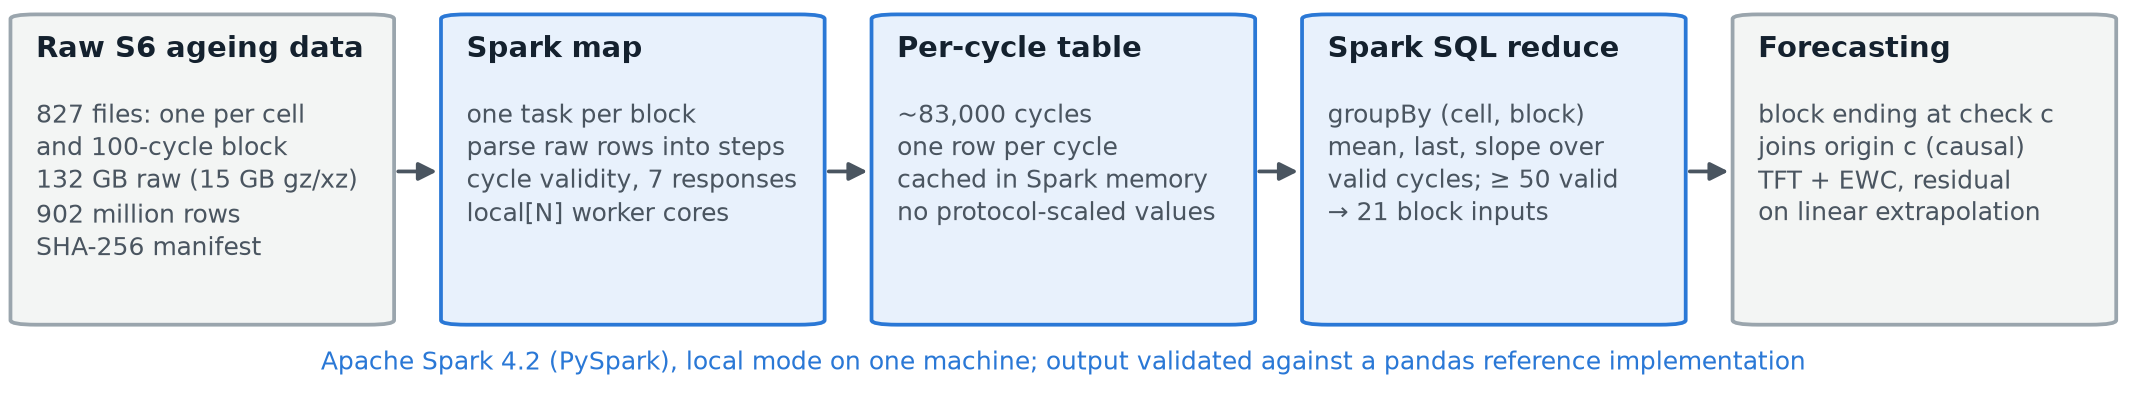

In [9]:
display(Image(filename=str(REPO_ROOT / "paper" / "figures" / "spark_pipeline.png"), width=900))

### 9.1 The data funnel: from raw rows to model inputs

In [10]:
rc = json.loads((REPO_ROOT / "results" / "s6_ageing_row_count.json").read_text())
rep = json.loads((REPO_ROOT / "results" / "d22_ageing_report.json").read_text())
val = json.loads((REPO_ROOT / "results" / "d22_spark_validation.json").read_text())
print("raw ageing files        :", rc["n_files"])
print("raw size (uncompressed) :", f"{rc['uncompressed_bytes'] / 1e9:.1f} GB")
print("raw data rows           :", f"{rc['data_rows']:,}")
print("per-cycle rows (map)    :", f"{val['cycles']:,}  (Spark run)")
print("blocks (reduce)         :", val["blocks"])
inputs = [k for k in val["per_input"] if k.endswith(("_mean", "_last", "_slope"))]
print("block inputs            :", len(inputs), "(7 responses x mean, last, slope) + valid/invalid cycle counts")
print("full run                :", val["engine"], f"- {val['seconds']:.0f} s")
cau = rep["causality"]
print("causality check         :", cau["blocks_checked"], "blocks;", cau["violations_at_valid_checks"],
      "end after a valid check;", cau["blocks_ending_at_or_after_check"], "ends at an invalid check", cau["violations"])
comp_tab = pd.DataFrame(rep["completeness"])
print("per cell (valid / invalid cycles, blocks below 50 valid cycles):")
display(comp_tab[["cell", "blocks_present", "valid_cycles", "invalid_cycles", "blocks_below_min_valid"]])

raw ageing files        : 827
raw size (uncompressed) : 131.9 GB
raw data rows           : 901,974,259
per-cycle rows (map)    : 82,529  (Spark run)
blocks (reduce)         : 827
block inputs            : 21 (7 responses x mean, last, slope) + valid/invalid cycle counts
full run                : Apache Spark 4.2.0 (PySpark), local[6] on one machine - 1175 s
causality check         : 827 blocks; 0 end after a valid check; 1 ends at an invalid check [{'cell': 'cell2a', 'cycle': 100, 'valid': False}]
per cell (valid / invalid cycles, blocks below 50 valid cycles):


,cell,blocks_present,valid_cycles,invalid_cycles,blocks_below_min_valid
0,cell1a,32,3102,95,0
1,cell1b,33,3196,103,0
2,cell1c,32,3101,95,0
3,cell2a,33,3194,106,0
4,cell2b,33,3204,96,0
5,cell2c,33,3202,98,0
6,cell3a,40,3772,128,2
7,cell3b,40,3787,113,2
8,cell4a,43,4170,130,0
9,cell4b,45,4390,110,0


### 9.2 Spark against pandas, block by block

In [11]:
print("criterion:", val["criterion"], "| blocks compared:", val["compared_blocks"], "| all match:", val["matches_pandas"])
pi = pd.DataFrame(val["per_input"]).T
display(pi.sort_values(pi.columns[0], ascending=False).head(21))

criterion: |spark - pandas| <= 1e-09 * |pandas| + 1e-12, same missing values | blocks compared: 827 | all match: True


,same_missing,max_abs,max_rel,within_tolerance
age_valid_cycles,True,0.0,0.0,True
age_v_end_discharge_last,True,0.0,0.0,True
age_internal_resistance_last,True,0.0,0.0,True
age_internal_resistance_mean,True,0.0,0.0,True
age_relax_after_discharge_slope,True,0.0,0.0,True
age_relax_after_discharge_last,True,0.0,0.0,True
age_relax_after_discharge_mean,True,0.0,0.0,True
age_relax_after_charge_slope,True,0.0,0.0,True
age_relax_after_charge_last,True,0.0,0.0,True
age_relax_after_charge_mean,True,0.0,0.0,True


### 9.3 What it looked like while running (Spark web UI, screenshots from the full 827-block run)

Jobs: the MAP job (one task per block) then the REDUCE jobs; the map stage with its 827 tasks; the executors (worker threads).

spark_ui_full_run_jobs.png


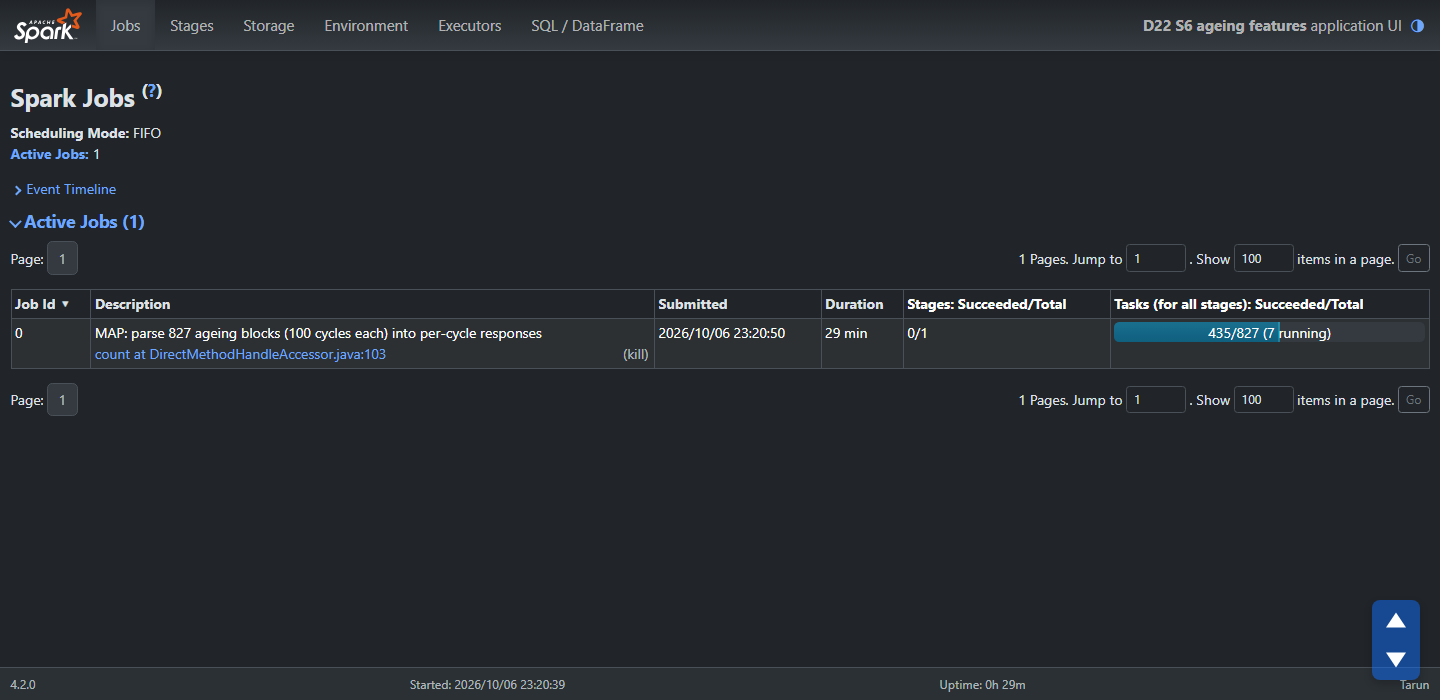

spark_ui_full_run_map_stage.png


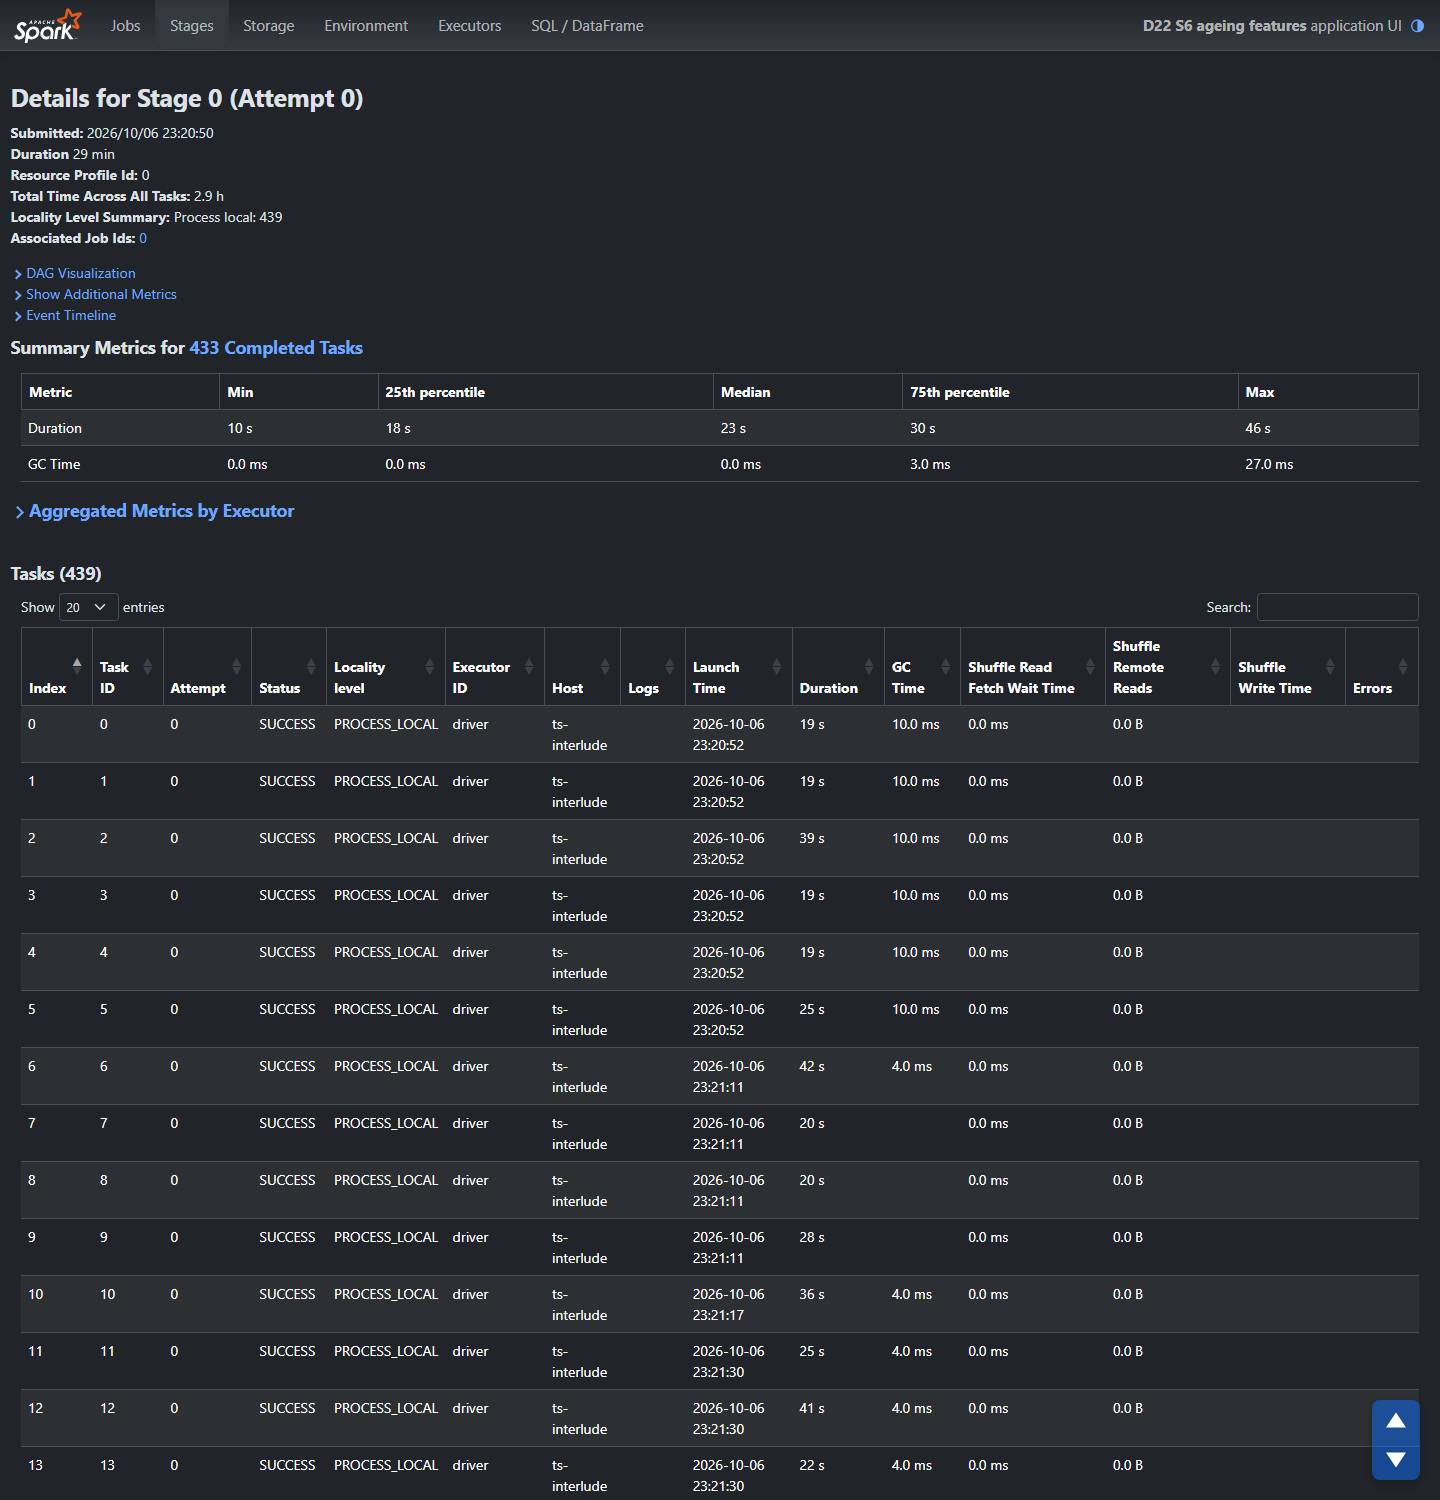

spark_ui_full_run_executors.png


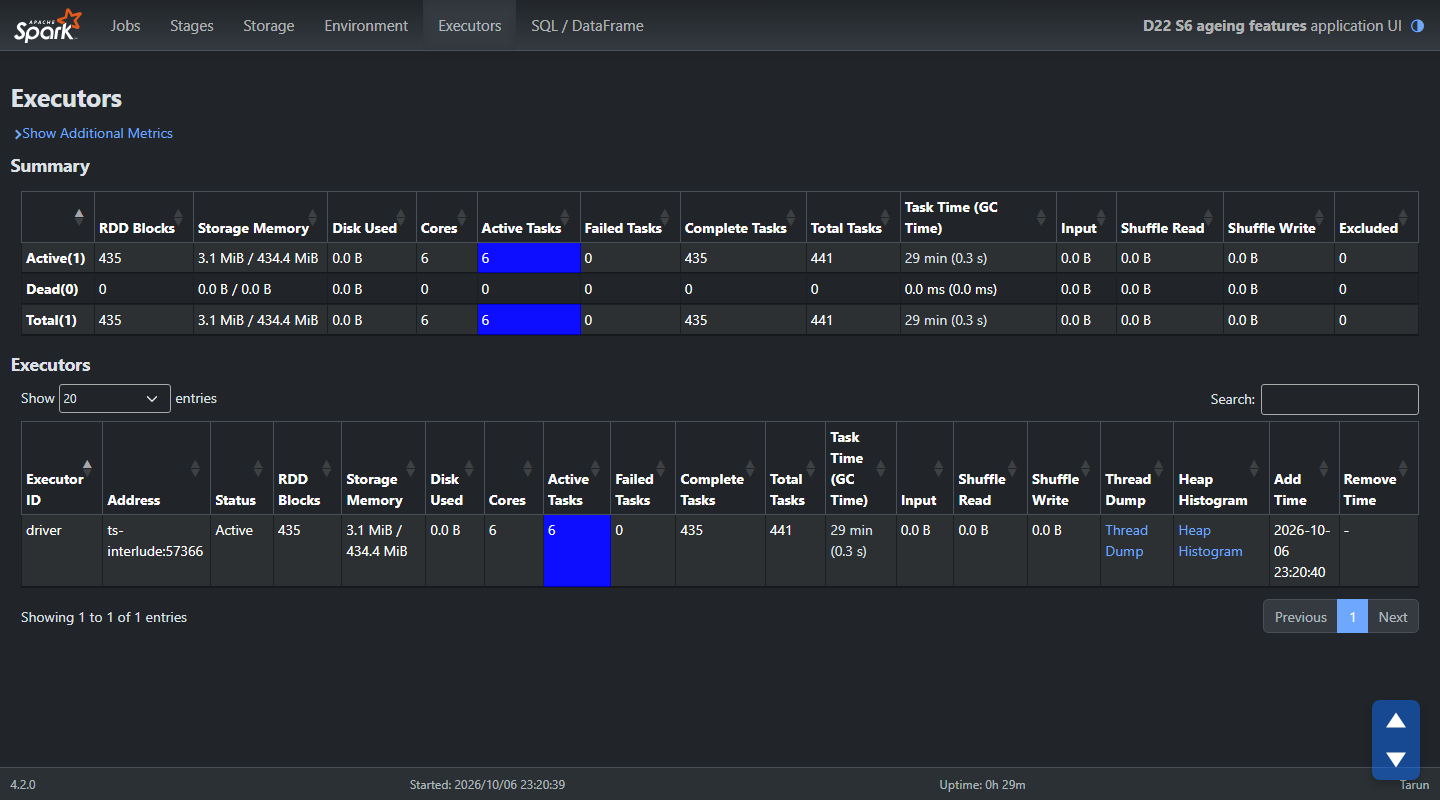

spark_ui_sql_plan.png


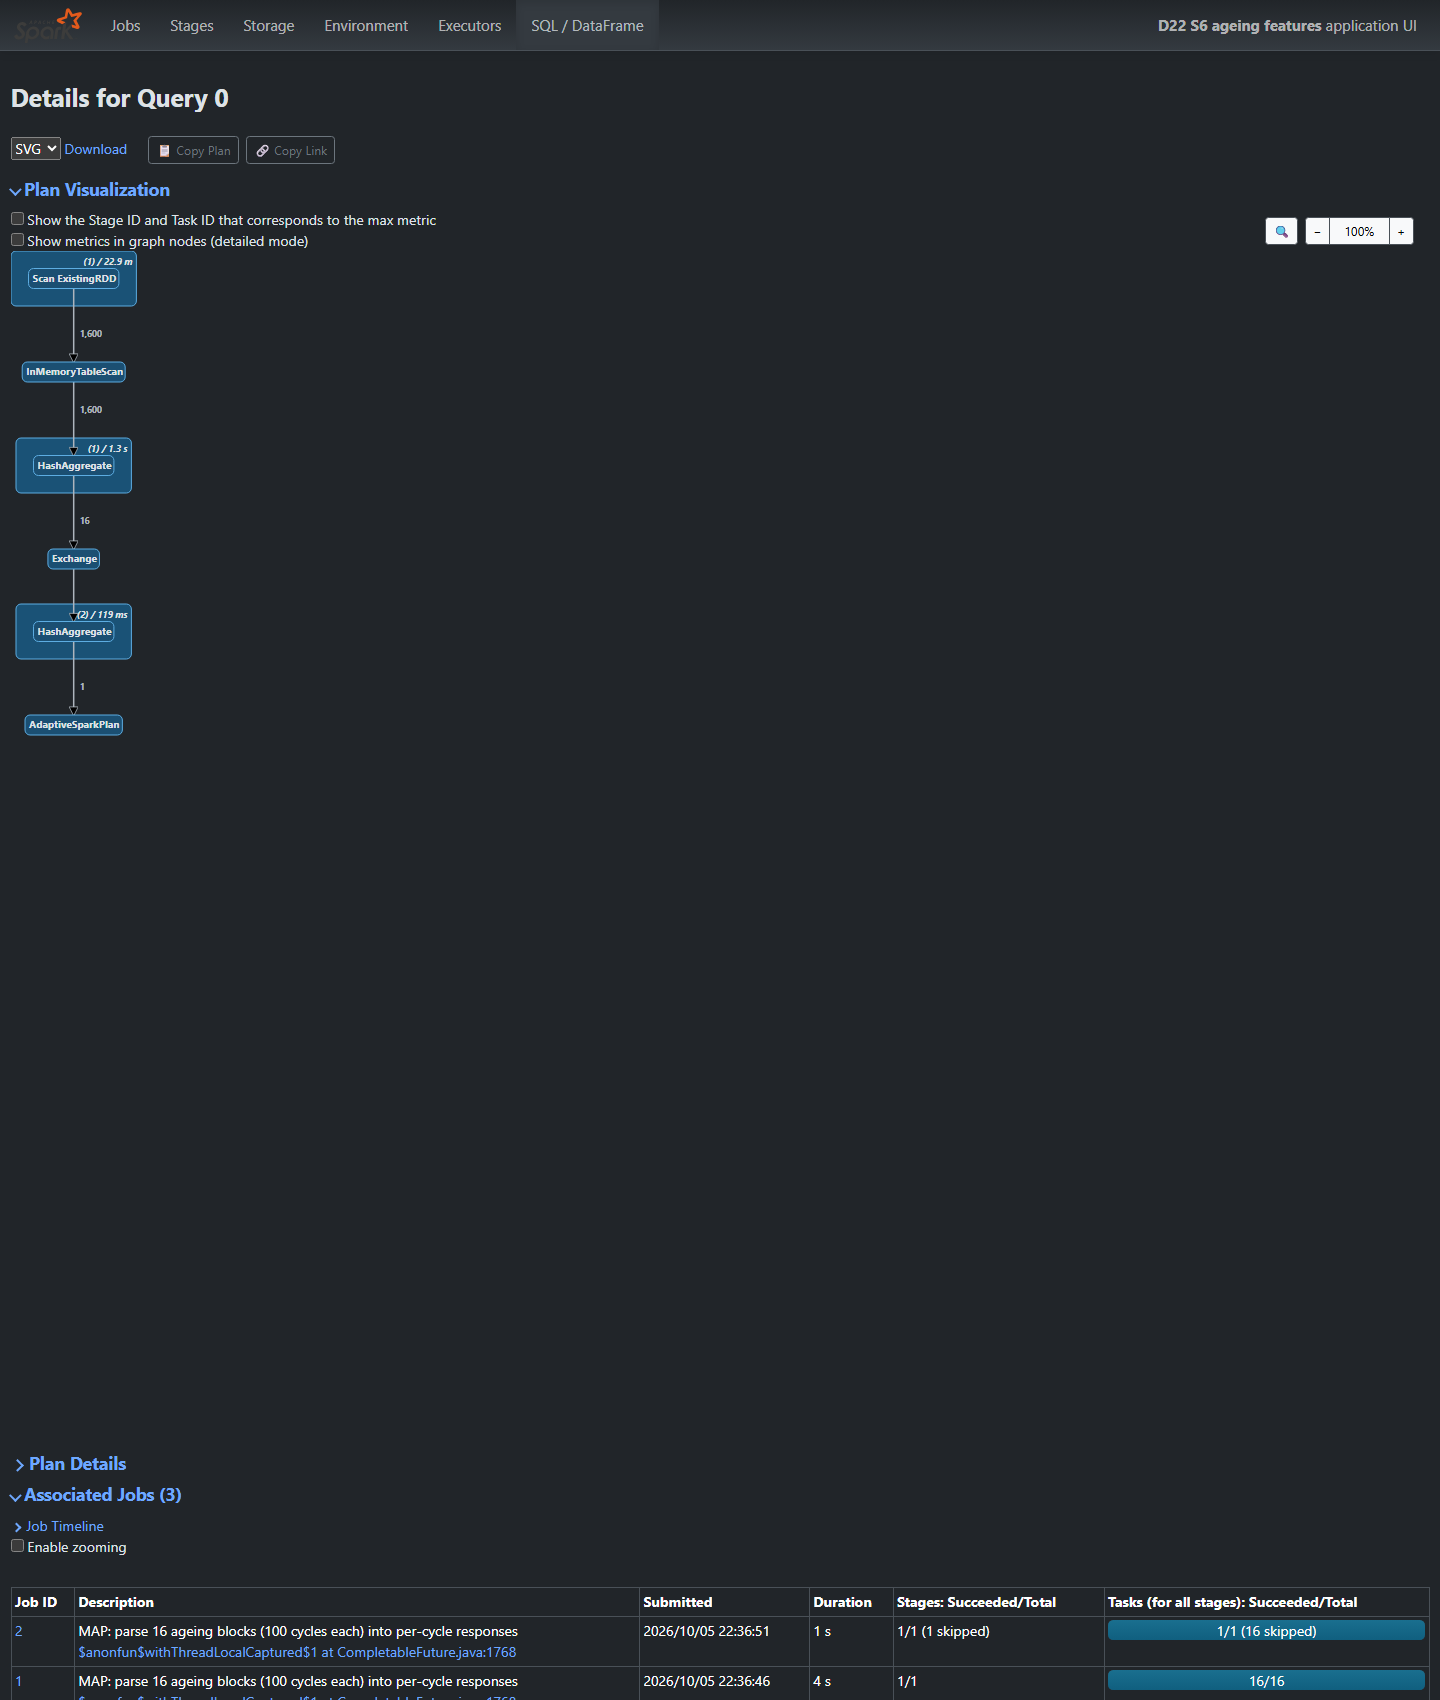

In [12]:
shots = REPO_ROOT / "docs" / "figures" / "spark"
for name in ("spark_ui_full_run_jobs.png", "spark_ui_full_run_map_stage.png", "spark_ui_full_run_executors.png", "spark_ui_sql_plan.png"):
    print(name)
    display(Image(filename=str(shots / name), width=900))

### 9.4 Leakage audit

Discharged charge, which is excluded, tracks the previous check's capacity almost perfectly within each cell (the protocol scales it), so using it would leak the label. The allowed responses carry health information without being set from the label.

In [13]:
q = pd.DataFrame(rep["audit_discharged_charge_vs_previous_capacity"])
print(f"EXCLUDED discharged charge vs previous check capacity, within cell: Pearson r = {q['pearson'].min():.3f}-{q['pearson'].max():.3f} over {len(q)} cells")
f2 = pd.DataFrame(rep["audit_f2_vs_origin_capacity"]).T
print("ALLOWED inputs vs origin capacity, within cell (Spearman rho):")
display(f2.round(3))

EXCLUDED discharged charge vs previous check capacity, within cell: Pearson r = 0.972-0.999 over 20 cells
ALLOWED inputs vs origin capacity, within cell (Spearman rho):


,n_cells,median_rho,max_abs_rho
age_v_end_charge_mean,20.0,-0.138,0.788
age_v_end_charge_last,20.0,-0.161,0.595
age_v_end_charge_slope,20.0,-0.020,0.507
age_cv_seconds_mean,10.0,0.905,0.969
age_cv_seconds_last,9.0,0.711,0.811
age_cv_seconds_slope,10.0,-0.147,0.476
age_cv_end_current_mean,9.0,-0.773,0.892
age_cv_end_current_last,9.0,-0.252,0.561
age_cv_end_current_slope,9.0,0.051,0.289
age_v_end_discharge_mean,20.0,0.200,0.996


### 9.5 Scaling run (D24 night, 120 blocks spread over the cells)

**Caveat:** the speed-up from 1 to 2 threads is above linear (efficiency > 1), which real parallelism cannot give. The 1-thread run, the first of the four, probably includes a one-off cost (for example a cold file cache or slow Python-worker start-up on Windows). This is not explained yet, so these numbers should **not** be reported as parallel efficiency. Every run matched pandas.

In [14]:
sc = json.loads((REPO_ROOT / "results" / "d22_spark_scaling.json").read_text())
display(pd.DataFrame(sc["runs"])[["cores", "status", "blocks", "cycles", "job_seconds", "speedup", "efficiency", "matches_pandas", "max_abs_diff"]])

,cores,status,blocks,cycles,job_seconds,speedup,efficiency,matches_pandas,max_abs_diff
0,1,ok,120,12046,1466.6,1.000,1.000,True,2.273737e-13
1,2,ok,120,12046,296.7,4.943,2.471,True,2.273737e-13
2,4,ok,120,12046,172.8,8.487,2.122,True,2.273737e-13
3,6,ok,120,12046,150.4,9.751,1.625,True,2.273737e-13


### 9.6 What the Spark inputs did for the forecasts (D22)

Adding the 21 Spark inputs to the residual TFT + EWC made it **worse** (0.480 / 0.501 pp against 0.339 / 0.314 pp with the shared inputs, replicated, `results/forecasting_d22_e1_f2.json`). The responses track the health level, which the SOH history already gives; with 21 extra inputs and 135–225 training samples per task they add variance. The Spark pipeline itself is validated and reusable; the inputs it produced are not used by the final models.